# Übung 03: Ein KI-System für eine medizinische Fragestellung


In dieser Übung wollen wir ein einfaches komplettes KI-System aufbauen. Dazu untersuchen wir exemplarisch, ob sich ein binärer Herzbefund aus bereits vorliegenden Untersuchungsdaten vorhersagen lässt.


## Aufgabe 1: Klausuraufgabe

Ein Forschungsteam möchte nach einer Belastungsuntersuchung vorhersagen, ob ein koronarer Herzbefund vorliegt. Die Untersuchungsergebnisse liegen in Tabellenform vor. Eine Zeile beschreibt eine Person. Die Zielklasse `herzkrankheit` ist **0** (kein entsprechender Befund) oder **1** (Befund vorhanden). Der Datensatz enthält 303 Personen, davon 164 mit Klasse 0 und 139 mit Klasse 1.

Jede Spalte repräsentiert ein erfasstes Feature. Die folgenden Spalten stehen zur Verfügung.

| Spalte | Bedeutung |
|:--|:--|
| `age` | Alter in Jahren |
| `sex` | Im Ausgangsdatensatz codiertes Geschlecht: 0 = weiblich, 1 = männlich |
| `cp` | Brustschmerztyp: 1 = typische Angina, 2 = atypische Angina, 3 = nicht-anginöser Schmerz, 4 = asymptomatisch |
| `trestbps` | Ruheblutdruck bei Aufnahme in mmHg |
| `chol` | Serumcholesterin in mg/dl |
| `thalach` | maximale Herzfrequenz während des Belastungstests |
| `exang` | belastungsinduzierte Angina: 0 = nein, 1 = ja |
| `oldpeak` | belastungsbedingte ST-Streckensenkung gegenüber Ruhe |
| `Krankenhaus` | aus welchem Krankenhaus stammen die Daten: Sacred Heart, Sankt-Helena, County General oder Seattle Grace |
| `urspruenglicher_befund` | ursprünglicher Diagnosewert 0–4, aus dem `herzkrankheit` gebildet wurde |

Das Modell soll für **neue Personen nach Abschluss des Belastungstests** eingesetzt werden.


### 1a) Zielgröße und Merkmale (5 Punkte)

1. Erläutern Sie, ob es sich um eine Regressions- oder Klassifikationsaufgabe handelt.
2. Nennen Sie zwei Merkmale, die für die Fragestellung plausibel relevant sein könnten, und begründen Sie Ihre Auswahl.
3. Nennen Sie zwei Merkmale, die bei der Modellbildung für Probleme sorgen könnten, und begründen Sie Ihre Auswahl.


Ihre Lösung:


1. Es handedlt um eine binäre Klassifikationsaufgabe (Die Zielgroße umfasst 2 klasse: 1= Befund vorhanden / 0= keine Entsprechende Befund)

2. -> Age: Das alter kann mit dem Risiko einer koronaren Herzkrankung zusammenhängen und damit informationen über die Zielklasse liefern.

    -> exang: Belastungsinduzierte Angina kann auf eine koronare Herzkrankung hinweisen. Das Merkmale ist zum vorgesehenen Vorhersagezeitpunkt nach dem Belastungstest verfügbar. 

3. -> Ursprunglicher_befund: Die Zielklasse wurde direkt aus diesem Diagnosewert gebildet. Seine Verwendung würde die gesuchte Antwort bereits verraten (Target Leakage Problem). Dementsprechend muss das Merkmal      ausgeschlossen werden.

    -> Krankenhaus: Die krankenhauszugehörigkeit kann Unterschiede in den Patientauswahl oder den Messverfahren abbilden, sodass das Modell standortspezifische Zusammenhänge lernt, die möglicheerweise schlecht übertragbar sind. Das Merkmal muss deshalb kritisch geprüft werden.   

    -> Das Geschlecht : da Frauen stark berücksuichtigen werden können


### 1b) Datenbegutachtung und Vorverarbeitung (4 Punkte)

1. Ordnen Sie jedes Feature einer der Kategorien Numerisch, Kategorial, oder Nominal zu.
2. Ordnen Sie vier verschiedene Features je einer medizinischen Datenart zu.


Ihre Lösung:


1. Numerisch: Age, trestbps, chol, thalach, oldpeak
    
    Kategorical / Nominal: sex, cp, exang, ursprunglicher_befund

    Nominal: Krankenhaus

2. Demographische Daten: sex, age

    Labordaten: chol (durch laboruntersuchung bestimmt)

    Physiologische Daten: trestbps (Der Ruheblutdruck beschreibt eine Körperliche Funktion)



### 1c) Einen Klassifikator bauen (6 Punkte)

Ein Decision-Tree-Klassifikator soll aus den zehn Merkmalen den binären Herzbefund vorhersagen. Sie können davon ausgehen, dass alle Merkmale vollständig erfasst wurden und keine Werte fehlen. Die folgende Tabelle nennt verschiedene Arbeitsschritte, um den Decision-Tree-Klassifikator aus den Daten zu entwickeln. Streichen Sie die ungeeigneten Schritte und nummerieren Sie die übrigen in einer sinnvollen Reihenfolge. Gibt es Schritte, die mehrmals ausgeführt werden sollten?

| Nummer | Schritt |
|:--:|:--|
| 5 | A: Den Decision Tree auf allen verfügbaren Daten trainieren. |
| Streichen (Da wir genauso unabhängige Evaluationsdaten brauchen) | B: Den Decision Tree auf allen verfügbaren Daten evaluieren. |
| 1 | C: Die Personen in Trainings-, Validierungs- und Testdaten aufteilen. |
| Srteichen (sonst Bias in den Daten (maybe), Einschränkung der Daten sowie Beeinträchtigung der Übertragbarkeit ) | D: Alle weiblichen Personen aus dem Datensatz löschen. |
| 4 | E: Den Decision Tree auf dem Validierungsdatensatz evaluieren und die Parameter des Decision Tree basierend auf diesem Ergebnis anpassen. |
| Streichen (Gefahr, dass es durch Überanpassung zu optimistisch ausfällt) | F: Die Trainingsgüte als unabhängige Schätzung der späteren Leistung verwenden. |
| 3 | G: Den Decision Tree auf dem Trainingsdatensatz trainieren.|
| 2    (Direkte Weitergabe der Zielinformetion vermeiden) | H: Die Features `Krankenhaus` und `urspruenglicher_befund` löschen. |
| Streichen (unnötig, Decision Tree braucht halt keine Normalisierung) | I: Features normalisieren. |
| Streichen (Sie sind relevante Merkmale und müssen deshalb für das Training behalten werden) | J: Die Features `trestbps` und `exang` löschen. |


Ihre Lösung:


Die Schritte G und E werden mehrmal ausgeführt. Nach jeder Hyperparameteranpassung wird jeweils auf den Trainingsdaten trainiert und auf den Validierungsdaten bewertet.

##### Es fehlt auch noch den folgenden Schritt: Das ausgewählte Modell muss ja auch noch einmal auf dem bislang unangetasteten Testdatensatz evaluiert.


## Aufgabe 2: Vorrechenaufgabe - eine einfache Baseline

In dieser Aufgabe liegt der in Aufgabe 1 eingeführte Beispieldatensatz tatsächlich vor, in Form der bereitgestellten CSV-Datei `herzkrankheit_cleveland.csv`. Eine Zeile beschreibt eine Person. Die elf Spalten enthalten zehn Features sowie `herzkrankheit`, die binäre Zielklasse. Für die Baseline übernehmen wir zunächst alle Eingabespalten ohne fachliche Merkmalsprüfung.

Die Daten sind eine abgewandelte Version der [Cleveland-Teilmenge des UCI-Heart-Disease-Datensatzes](https://archive.ics.uci.edu/dataset/45/heart+disease) (CC BY 4.0).


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score, recall_score

# Wenn ihr eure Daten in Google Drive hochgeladen habt (empfohlen - eventuell Ordner noch anpassen; MyDrive heißt in der deutschen Drive-Version "Meine Ablage"):
#from google.colab import drive
#drive.mount("/content/drive")
dateipfad = "C:\\Users\\steve\\Desktop\\Master\\Semester_2\\KI_in_Med\\Übungen\\KI-in-der-Medizin\\src\\Daten\\herzkrankheit_cleveland.csv"
daten = pd.read_csv(dateipfad)
display(daten.head())
print("Form:", daten.shape)
print("Zielklassen:", daten["herzkrankheit"].value_counts().sort_index().to_dict())
print("Fehlende Werte:", int(daten.isna().sum().sum()))


,age,sex,cp,trestbps,chol,thalach,exang,oldpeak,Krankenhaus,urspruenglicher_befund,herzkrankheit
0,63,1,1,145,233,150,0,2.3,Sankt-Helena,0,0
1,67,1,4,160,286,108,1,1.5,Sacred Heart,2,1
2,67,1,4,120,229,129,1,2.6,Sankt-Helena,1,1
3,37,1,3,130,250,187,0,3.5,County General,0,0
4,41,0,2,130,204,172,0,1.4,Sacred Heart,0,0


Form: (303, 11)
Zielklassen: {0: 164, 1: 139}
Fehlende Werte: 0


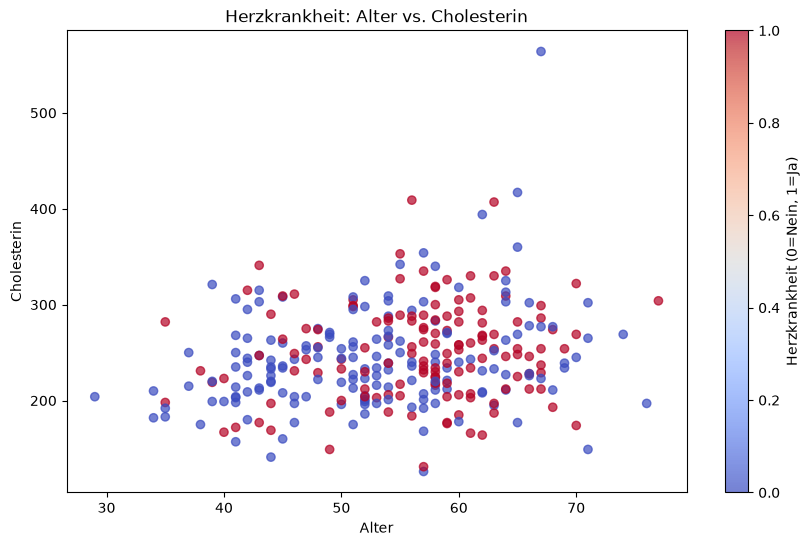

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(daten["age"], daten["chol"], c=daten["herzkrankheit"], cmap="coolwarm", alpha=0.7)
plt.title("Herzkrankheit: Alter vs. Cholesterin")
plt.xlabel("Alter")
plt.ylabel("Cholesterin")
plt.colorbar(label="Herzkrankheit (0=Nein, 1=Ja)")
plt.show()

Um die Features von der Zielgröße zu trennen, teilen wir das DataFrame in die Featurematrix `X` und den Zielvektor `y`. Zunächst reservieren wir 20 % der Personen als Testdaten. Vom Rest verwenden wir ein Viertel zur Validierung. Dafür nutzen wir die Funktion `train_test_split` der Bibiothek `sklearn`. Der Parameter `stratify` hält die Klassenanteile in den Teilmengen ungefähr konstant. Der `random_state` macht den Vergleich reproduzierbar. Die Testdaten bleiben zunächst unangetastet.


In [3]:
X = daten.drop(columns="herzkrankheit")
y = daten["herzkrankheit"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42
)
print("Training, Validierung, Test:", len(X_train), len(X_val), len(X_test))


Training, Validierung, Test: 181 61 61


Ein kleiner Entscheidungsbaum ist eine leicht nachvollziehbare Referenz. Er kann jedoch textbasierte Features nicht unmittelbar verarbeiten. Deshalb codiert die vorbereitete Pipeline die vier Krankenhausnamen als getrennte 0/1-Spalten. Erneut nutzen wir die Bibliothek `sklearn`, insbesondere die Klasse `DecisionTreeClassifier`, sowie den `ColumnTranformer` und einen `OneHotEncoder` für die Vorverarbeitung; alles organisiert in einer `Pipeline`.
Der Parameter `max_depth=3` begrenzt die Baumtiefe. `fit` lernt ausschließlich aus den Trainingsdaten; die Vorhersagen prüfen wir auf der Validierung.


,Vorhersage 0,Vorhersage 1
wahr 0,33,0
wahr 1,0,28


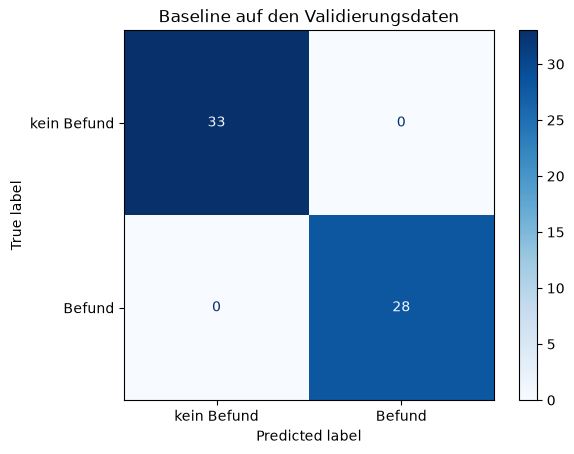

Accuracy: 1.0
Recall für Befund: 1.0


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Technische Codierung der Textspalte; alle übrigen Eingaben werden übernommen.
baseline = Pipeline([
    ("vorverarbeitung", ColumnTransformer(
        [("krankenhaus", OneHotEncoder(handle_unknown="ignore"), ["Krankenhaus"])],
        remainder="passthrough"
    )),
    ("baum", DecisionTreeClassifier(max_depth=3, random_state=42)),
])
baseline.fit(X_train, y_train)
vorhersage_basis_val = baseline.predict(X_val)

matrix_basis_val = confusion_matrix(y_val, vorhersage_basis_val, labels=[0, 1])
display(pd.DataFrame(matrix_basis_val, index=["wahr 0", "wahr 1"], columns=["Vorhersage 0", "Vorhersage 1"]))
ConfusionMatrixDisplay(matrix_basis_val, display_labels=["kein Befund", "Befund"]).plot(cmap="Blues", values_format="d")
plt.title("Baseline auf den Validierungsdaten")
plt.show()
print("Accuracy:", round(accuracy_score(y_val, vorhersage_basis_val), 3))
print("Recall für Befund:", round(recall_score(y_val, vorhersage_basis_val), 3))


In der Matrix stehen links oben richtig negative und rechts unten richtig positive Fälle. Links unten sind falsch negative Fälle und rechts oben falsch positive. Die Accuracy erfasst alle korrekten Entscheidungen; der Recall der Klasse 1 betrachtet nur tatsächlich positive Fälle.

Die Validierungsmatrix enthält keinerlei falsch klassifizierte Samples. Die Accuracy beträgt 100 %, ebenso der Recall. Entweder, wir haben das Problem perfekt gelöst oder ein paar entscheidende Fehler gemacht.


## Aufgabe 3: Eigenarbeit – ein verwendbares Modell prüfen

Die Baseline berücksichtigt weder die Sinnhaftigkeit noch die Datenherkunft oder -verfügbarkeit. Eine hohe Kennzahl allein belegt deshalb noch kein gutes KI-System. Prüft zuerst die Merkmale (dabei könnt ihr euch an den Ergebnissen der Klausuraufgabe orientieren) und vergleicht danach einen bereinigten Baum mit einer logistischen Regression. Ziel ist ein Vergleich anhand der Validierungsdaten. Entscheidet vor der abschließenden Testauswertung, welches der beiden bereinigten Modelle ihr bevorzugt.


### 3a) Daten und Merkmale prüfen

Untersucht die Trainingsdaten mithilfe des vorbereiteten Codes. Die erste Tabelle zeigt eine generelle Datenübersicht mithilfe der Funktion `describe` der Bibliothek `pandas`, inklusive Klassenhäufigkeit, Gruppenhäufigkeit, Wertebereiche und statistischen Kennzahlen der Spalten.

Tabelle zwei zeigt die Häufigkeit der Werte für die Spalte `urspruenglicher_befund`, getrennt nach den Werten für `herzkrankheit`.

Tabelle drei zeigt die Häufigkeit der Werte für die Spalte `sex`, getrennt nach den Werten für `herzkrankheit`.


In [5]:
trainingsdaten = pd.concat([X_train, y_train], axis=1)
display(trainingsdaten.describe(include="all").T)
display(pd.crosstab(X_train["urspruenglicher_befund"], y_train,
                    rownames=["urspruenglicher_befund"], colnames=["herzkrankheit"]))
display(pd.crosstab(X_train["sex"], y_train, rownames=["sex"], colnames=["herzkrankheit"]))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,181.0,NaN,NaN,NaN,54.353591,9.117556,29.0,47.0,56.0,62.0,76.0
sex,181.0,NaN,NaN,NaN,0.651934,0.477679,0.0,0.0,1.0,1.0,1.0
cp,181.0,NaN,NaN,NaN,3.20442,0.923269,1.0,3.0,3.0,4.0,4.0
trestbps,181.0,NaN,NaN,NaN,130.38674,17.732727,94.0,120.0,130.0,140.0,200.0
chol,181.0,NaN,NaN,NaN,247.254144,54.293662,126.0,211.0,243.0,273.0,564.0
thalach,181.0,NaN,NaN,NaN,149.314917,22.818493,71.0,133.0,152.0,165.0,202.0
exang,181.0,NaN,NaN,NaN,0.309392,0.463525,0.0,0.0,0.0,1.0,1.0
oldpeak,181.0,NaN,NaN,NaN,1.030387,1.079513,0.0,0.0,0.8,1.6,6.2
Krankenhaus,181,4,Sankt-Helena,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urspruenglicher_befund,181.0,NaN,NaN,NaN,0.878453,1.176922,0.0,0.0,0.0,1.0,4.0


herzkrankheit,0,1
urspruenglicher_befund,,
0,98,0
1,0,38
2,0,22
3,0,15
4,0,8


herzkrankheit,0,1
sex,,
0,47,16
1,51,67


Wählt Merkmale aus, die nach dieser Prüfung vor einer sinnvollen Modellbildung entfernt werden sollten. Tragt die übrigen Merkmale in die Liste `merkmale` im vorbereiteten Code ein.

Ihre Lösung:


urspruenglicher_befund: Die Kreuztabelle zeigt eine eindeutige Zuordnung: Befund 0 bedeutet immer herzkrankheit = 0, Befund 1–4 immer herzkrankheit = 1. Das Merkmal verrät somit die Zielklasse und muss wegen Target Leakage ausgeschlossen werden.

Krankenhaus: Wie in der vorherigen Aufgabe wird die Krankenhauszugehörigkeit ausgeschlossen, um die direkte Nutzung möglicher standortspezifischer Besonderheiten zu vermeiden. Die gezeigten Tabellen allein beweisen allerdings nicht, dass dieses Merkmal schädlich ist.


In [33]:
# Tragt die fachlich begründeten Eingabespalten ein.
merkmale = [  
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "thalach",
    "exang",
    "oldpeak",] # Hier ihre Lösung
print("Gewählte Modellmerkmale:", merkmale)

Gewählte Modellmerkmale: ['age', 'sex', 'cp', 'trestbps', 'chol', 'thalach', 'exang', 'oldpeak']


### 3b) Bereinigten Baum und lineares Modell vergleichen

Trainiert zuerst denselben Baum nur mit den ausgewählten Merkmalen. Dadurch entsteht eine gültige Referenz für die Alternative. Die ursprüngliche Baseline mit allen Spalten bleibt als Beispiel für eine irreführende Bewertung erhalten.

Für die logistische Regression behandeln wir `cp` als Kategorie mit einer One-Hot-Codierung. Dies empfiehlt sich bei kategorialen Daten, da keine künstliche Ordnung und gleiche Abstände zwischen den Codes angenommen werden. Die übrigen Größen werden skaliert. Die `Pipeline` passt diese Schritte ausschließlich auf dem Training an.

Vergleicht mehrere Werte für `C`; ein kleineres `C` bedeutet stärkere Regularisierung - das genaue Verständnis ist nicht entscheidend. Wichtig ist nur, dass es sich hier um einen Hyperparameter handelt. Ergänzt die markierten Schritte.

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

kategorial = ["cp"]
numerisch = [name for name in merkmale if name not in kategorial]

vorverarbeitung = ColumnTransformer([
    ("skaliert", StandardScaler(), numerisch),
    ("kategorien", OneHotEncoder(handle_unknown="ignore"), kategorial),
])

bereinigte_baseline = Pipeline([
    ("vorverarbeitung", vorverarbeitung),
    ("klassifikator", DecisionTreeClassifier(max_depth=3, random_state=42)),
])
bereinigte_baseline.fit(X_train[merkmale], y_train)
vorhersage_bereinigt_val = bereinigte_baseline.predict(X_val[merkmale])
print("Bereinigter Baum, Balanced Accuracy:",
      round(balanced_accuracy_score(y_val, vorhersage_bereinigt_val), 3))
print("Bereinigter Baum, Recall Klasse 1:",
      round(recall_score(y_val, vorhersage_bereinigt_val), 3))
print("=======================================")
print("Ergebnisse der logistischen Regression:")

C_werte = [0.01, 0.1, 1.0, 10.0] # Hier dein Code
modelle = []
ergebnisse = []
for C in C_werte:
    modell = Pipeline([
        ("vorverarbeitung", vorverarbeitung),
        ("klassifikator", LogisticRegression(C=C, class_weight="balanced", max_iter=1000)),
    ])
    # Ergänzt Modellanpassung und Vorhersage.
    modell.fit(X_train[merkmale], y_train)
    vorhersage = modell.predict(X_val[merkmale]) # Hier dein Code
    modelle.append(modell)
    ergebnisse.append({
        "C": C,
        "Balanced Accuracy": balanced_accuracy_score(y_val, vorhersage),
        "Recall Klasse 1": recall_score(y_val, vorhersage),
    })

vergleich = pd.DataFrame(ergebnisse)
display(vergleich.round(3))


Bereinigter Baum, Balanced Accuracy: 0.71
Bereinigter Baum, Recall Klasse 1: 0.571
Ergebnisse der logistischen Regression:


,C,Balanced Accuracy,Recall Klasse 1
0,0.01,0.787,0.786
1,0.10,0.787,0.786
2,1.00,0.790,0.821
3,10.00,0.805,0.821


Wählt anhand der Validierung ein `C`. Berücksichtigt neben der balancierten Genauigkeit den Recall positiver Fälle. Wie schneidet die Alternative gegenüber dem bereinigten Baum ab? Tragt eure Wahl im folgenden Code ein und schaut euch die Confusion Matrix an.


Ihre Lösung:


Ich würde die logistische Regression mit C = 10 wählen. Sie erreicht unter den gezeigten Kandidaten die höchste Balanced Accuracy und gemeinsam mit C = 1 den höchsten Recall.

Die logistische Regression erkennt somit 82,1 % der positiven Fälle, der Baum nur 57,1 %.

In [22]:
# Tragt hier den gewählten Wert aus C_werte ein.
gewaehltes_C = 10.0 # Hier dein Code
auswahl = C_werte.index(gewaehltes_C)
modell_gewaehlt = modelle[auswahl]
vorhersage_modell_val = modell_gewaehlt.predict(X_val[merkmale])
display(pd.DataFrame(
    confusion_matrix(y_val, vorhersage_modell_val, labels=[0, 1]),
    index=["wahr 0", "wahr 1"], columns=["Vorhersage 0", "Vorhersage 1"]
))

,Vorhersage 0,Vorhersage 1
wahr 0,26,7
wahr 1,5,23


### 3c) Gruppenbezogene Fehler prüfen

Vergleicht für die beiden im Ausgangsdatensatz codierten Geschlechtsgruppen den Recall der positiven Klasse. Die gegebene Funktion `gruppen_recall` gibt auch die Zahl tatsächlich positiver Fälle aus, damit ihr kleine Nenner erkennt. `sex` dient hier als Prüfvariable und ist unabhängig davon verfügbar, ob ihr es als Modelleingabe gewählt habt.


In [25]:
def gruppen_recall(y_wahr, y_prognose, gruppen):
    """Calculate recall for class 1 separately for groups 0 and 1.

    Parameters
    ----------
    y_wahr : pandas.Series
        True binary labels (0 or 1).
    y_prognose : numpy.ndarray
        Predicted binary labels, in the same row order as y_wahr.
    gruppen : pandas.Series
        Group membership (0 or 1), in the same row order as y_wahr.

    Returns
    -------
    pandas.DataFrame
        One row per group, with the group value ("sex"), the number of
        actual positive cases ("tatsächlich positiv"), and recall for
        class 1 ("Recall Klasse 1")."""
    zeilen = []
    for gruppe in [0, 1]:
        maske = (gruppen.to_numpy() == gruppe)
        positive = int(y_wahr.to_numpy()[maske].sum())
        recall = recall_score(y_wahr.to_numpy()[maske], y_prognose[maske], zero_division=0)
        zeilen.append({"sex": gruppe, "tatsächlich positiv": positive, "Recall Klasse 1": recall})
    return pd.DataFrame(zeilen)

print("Decision Tree, Validierung")
display(gruppen_recall(y_val, vorhersage_bereinigt_val, X_val["sex"])) # Hier dein Code
print("Logistische Regression, Validierung")
display(gruppen_recall(y_val, vorhersage_modell_val, X_val["sex"])) # Hier dein Code


Decision Tree, Validierung


,sex,tatsächlich positiv,Recall Klasse 1
0,0,2,0.500000
1,1,26,0.576923


Logistische Regression, Validierung


,sex,tatsächlich positiv,Recall Klasse 1
0,0,2,0.500000
1,1,26,0.846154


Unterscheiden sich die Gruppen-Recalls? Wie belastbar ist der Vergleich angesichts der Fallzahlen? Benennt mindestens eine zusätzliche Prüfung, die vor einem klinischen Einsatz nötig wäre.


Ihre Lösung:


Die logistische Regression verbessert den Recall in dieser Validierungsstichprobe nur bei Männern. Der Unterschied zwischen den Gruppen beträgt beim Baum etwa 7,7 Prozentpunkte, bei der logistischen Regression etwa 34,6 Prozentpunkte.

Der Vergleich ist jedoch nur eingeschränkt belastbar: Bei Frauen liegen lediglich zwei tatsächlich positive Fälle vor. Ein einziger zusätzlich erkannter Fall würde den Recall bereits um 50 Prozentpunkte verändern. Deshalb lässt sich daraus keine verlässliche Aussage über einen systematischen Leistungsunterschied zwischen den Geschlechtern ableiten.

Vor einem klinischen Einsatz wäre eine Validierung auf unabhängigen Daten mit ausreichend vielen positiven Fällen je Gruppe, möglichst aus weiteren Krankenhäusern, erforderlich. Maybe: Zusätzlich sollten Konfidenzintervalle für die Gruppen-Recalls angegeben werden, um die Unsicherheit sichtbar zu machen. 


### 3d) Abschließender Vergleich auf den Testdaten

Nach der Modellauswahl trainieren wir den bereinigten Baum und die gewählte logistische Regression erneut auf Training **und** Validierung. Erst danach betrachten wir die bisher zurückgehaltenen Testdaten.


In [41]:
from sklearn.base import clone

abschluss_basis = DecisionTreeClassifier(max_depth=3, random_state=42)
abschluss_basis.fit(X_train[merkmale], y_train) # Hier dein Code

abschluss_modell = clone(modell_gewaehlt)
abschluss_modell.fit(X_train[merkmale], y_train) # Hier dein Code

prognose_basis_test = abschluss_basis.predict(X_test[merkmale]) # Hier dein Code
prognose_modell_test = abschluss_modell.predict(X_test[merkmale]) # Hier dein Code

for name, prognose in [("Decision Tree", prognose_basis_test), ("Logistische Regression", prognose_modell_test)]:
    print("==============================================")
    print(name)
    display(pd.DataFrame(confusion_matrix(y_test, prognose, labels=[0, 1]),
                         index=["wahr 0", "wahr 1"], columns=["Vorhersage 0", "Vorhersage 1"]))
    print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, prognose), 3))
    print("Recall Klasse 1:", round(recall_score(y_test, prognose), 3))
    display(gruppen_recall(y_test, prognose, X_test["sex"]).round(3))


Decision Tree


,Vorhersage 0,Vorhersage 1
wahr 0,26,7
wahr 1,5,23


Balanced Accuracy: 0.805
Recall Klasse 1: 0.821


,sex,tatsächlich positiv,Recall Klasse 1
0,0,7,1.000
1,1,21,0.762


Logistische Regression


,Vorhersage 0,Vorhersage 1
wahr 0,28,5
wahr 1,2,26


Balanced Accuracy: 0.889
Recall Klasse 1: 0.929


,sex,tatsächlich positiv,Recall Klasse 1
0,0,7,1.000
1,1,21,0.905


Vergleiche abschließend die beiden Modelle. Welche Aussagen kannst du treffen bzgl. der Gesamtperformance und der Performance auf dem geschützten Attribut? Kann man daraus finale Aussagen ziehen? Warum (nicht)?

Ihre Lösung:


Die logistische Regression erkennt insgesamt mehr positive Fälle und erzeugt zugleich weniger falsch positive Vorhersagen. Der Unterschied zwischen den Gruppen-Recalls fällt mit 9,5 Prozentpunkten geringer aus als beim Baum mit 23,8 Prozentpunkten.

Endgültige Aussagen über klinische Eignung oder Fairness sind daraus nicht möglich. Der Testdatensatz umfasst nur 61 Personen, darunter lediglich sieben tatsächlich positive Frauen. Ein Recall von 100 % bei diesen sieben Fällen garantiert keine perfekte Erkennung bei neuen Patientinnen. Zudem war der Recall bei Frauen in der Validierung niedriger als bei Männern; der Richtungswechsel verdeutlicht die Unsicherheit der kleinen Gruppenstichproben.

Erforderlich wären weitere unabhängige Validierungen mit größeren Fallzahlen je Gruppe und Konfidenzintervallen. Zusätzlich sollten weitere gruppenspezifische Fehlermaße, etwa die Falsch-Positiv-Rate, betrachtet werden.
